# Homework 4: Evaluation Metrics for Classification (ML Zoomcamp 2026)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

%matplotlib inline

## Data Preparation

In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
# Identificar variables categóricas y numéricas (excluyendo el target 'converted')
categorical = list(df.dtypes[df.dtypes == 'object'].index)
numerical = [c for c in df.columns if c not in categorical and c != 'converted']

print('Categorical:', categorical)
print('Numerical:', numerical)

# Reemplazar valores nulos según el enunciado
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print('\nMissing values after imputation:')
print(df.isnull().sum())

Categorical: []
Numerical: ['lead_source', 'industry', 'employment_status', 'location', 'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

Missing values after imputation:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [4]:
# Partición exacta indicada en las instrucciones
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

## Question 1: ROC AUC feature importance

In [5]:
q1_features = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
auc_scores = {}

for col in q1_features:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    auc_scores[col] = auc
    print(f'{col:25s}: {auc:.4f}')

best_feature = max(auc_scores, key=auc_scores.get)
print(f'\n--> Respuesta Q1: {best_feature}')

lead_score               : 0.7882
number_of_courses_viewed : 0.7230
interaction_count        : 0.7649
annual_income            : 0.6082

--> Respuesta Q1: lead_score


## Question 2: Training the model

In [6]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_pred)

print(f'Validation AUC: {val_auc:.4f}')
print(f'--> Respuesta Q2 (redondeado a 3 dígitos): {val_auc:.3f}')

Validation AUC: 0.7319
--> Respuesta Q2 (redondeado a 3 dígitos): 0.732


## Question 3: Precision and Recall

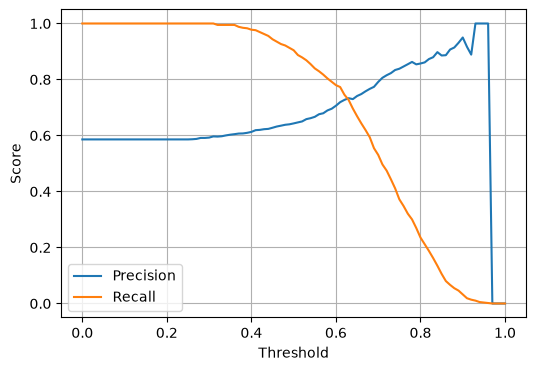

--> Respuesta Q3 (umbral de intersección): 0.63


In [7]:
thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    scores.append((t, p, r))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

plt.figure(figsize=(6, 4))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()

# Ignorar umbrales donde ambas métricas son 0 y buscar la menor diferencia absoluta
valid_scores = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid_scores['diff'] = np.abs(valid_scores.precision - valid_scores.recall)
best_t_q3 = valid_scores.loc[valid_scores['diff'].idxmin(), 'threshold']

print(f'--> Respuesta Q3 (umbral de intersección): {best_t_q3:.2f}')

## Question 4: F1 score

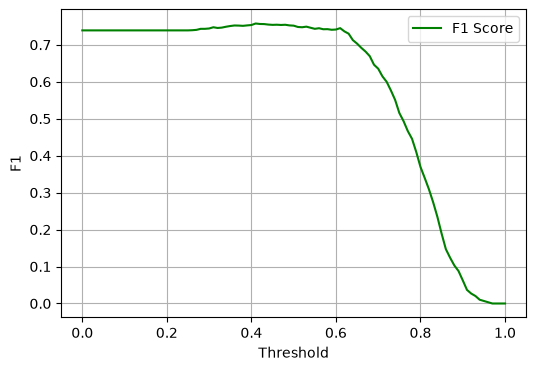

Max F1: 0.7576
--> Respuesta Q4 (umbral con F1 máximo): 0.41


In [8]:
df_scores['f1'] = np.where(
    (df_scores.precision + df_scores.recall) > 0,
    2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall),
    0.0
)

plt.figure(figsize=(6, 4))
plt.plot(df_scores.threshold, df_scores.f1, label='F1 Score', color='green')
plt.xlabel('Threshold')
plt.ylabel('F1')
plt.legend()
plt.grid(True)
plt.show()

best_idx_q4 = df_scores['f1'].idxmax()
best_t_q4 = df_scores.loc[best_idx_q4, 'threshold']
max_f1 = df_scores.loc[best_idx_q4, 'f1']

print(f'Max F1: {max_f1:.4f}')
print(f'--> Respuesta Q4 (umbral con F1 máximo): {best_t_q4:.2f}')

## Question 5: 5-Fold CV

In [9]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
cv_scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = df_train_fold.converted.values
    y_val_fold = df_val_fold.converted.values

    dv, model = train(df_train_fold, y_train_fold, C=1.0)
    y_pred_fold = predict(df_val_fold, dv, model)

    auc = roc_auc_score(y_val_fold, y_pred_fold)
    cv_scores.append(auc)

std_cv = np.std(cv_scores)
print(f'5-Fold AUC scores: {[round(s, 4) for s in cv_scores]}')
print(f'Mean AUC: {np.mean(cv_scores):.4f}')
print(f'--> Respuesta Q5 (Std across folds): {std_cv:.3f}')

5-Fold AUC scores: [0.7305, 0.7297, 0.7363, 0.7413, 0.721]
Mean AUC: 0.7318
--> Respuesta Q5 (Std across folds): 0.007


## Question 6: Hyperparameter Tuning

In [10]:
c_values = [0.000001, 0.001, 1]
tuning_results = []

for C in c_values:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        y_train_fold = df_train_fold.converted.values
        y_val_fold = df_val_fold.converted.values

        dv, model = train(df_train_fold, y_train_fold, C=C)
        y_pred_fold = predict(df_val_fold, dv, model)

        auc = roc_auc_score(y_val_fold, y_pred_fold)
        scores.append(auc)

    mean_score = round(np.mean(scores), 3)
    std_score = round(np.std(scores), 3)
    tuning_results.append((C, mean_score, std_score))
    print(f'C={C:<10} -> Mean AUC = {mean_score:.3f} +- {std_score:.3f}')

# Regla de desempate: mayor media -> menor desviación estándar -> menor C
best_c_result = sorted(tuning_results, key=lambda x: (-x[1], x[2], x[0]))[0]
print(f'\n--> Respuesta Q6 (Best C): {best_c_result[0]}')

C=1e-06      -> Mean AUC = 0.617 +- 0.019
C=0.001      -> Mean AUC = 0.749 +- 0.010
C=1          -> Mean AUC = 0.732 +- 0.007

--> Respuesta Q6 (Best C): 0.001
